<a href="https://colab.research.google.com/github/Ashritha002/fuzzy-tutorial/blob/main/Travelease_projectnotebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TravelEase

Fuzzy Sets and Systems - Project Notebook

This notebook applies fuzzy logic to TravelEase, following the three input areas from slide 5:

1. Student state: Language proficiency, familiarity, and stress.
2. Communication peer: Cooperation, language adaptation, and human/self-service support.
3. Scenario: Time pressure, information completeness, and situation criticality.

The system uses fuzzy levels to recommend low, moderate, or high assistance.


In [1]:
%pip -q install scikit-fuzzy

import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

print("Libraries imported successfully.")


Libraries imported successfully.


## Define the fuzzy variables
1. We use low, medium and high to describe each input, such as language proficiency, stress and time pressure

2. We consider the student, the person or service they interact with, and the situation to decide how much help TravelEase should provide


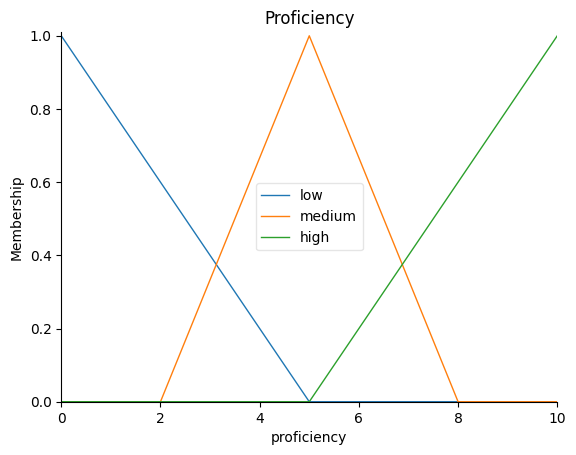

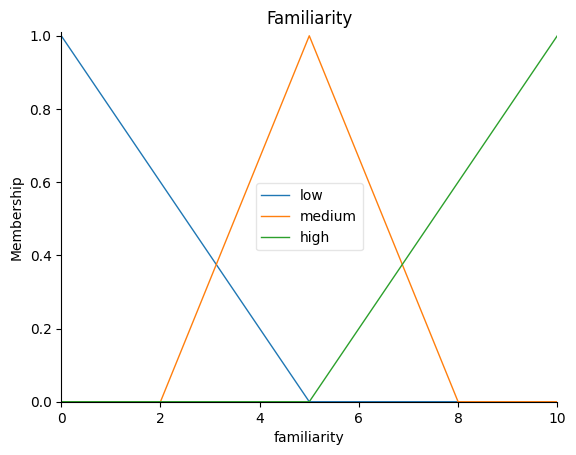

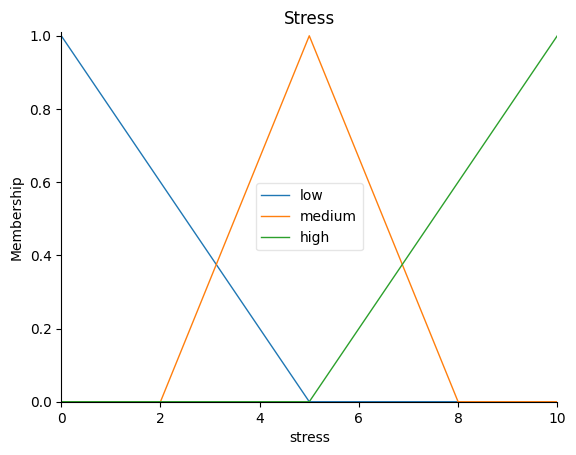

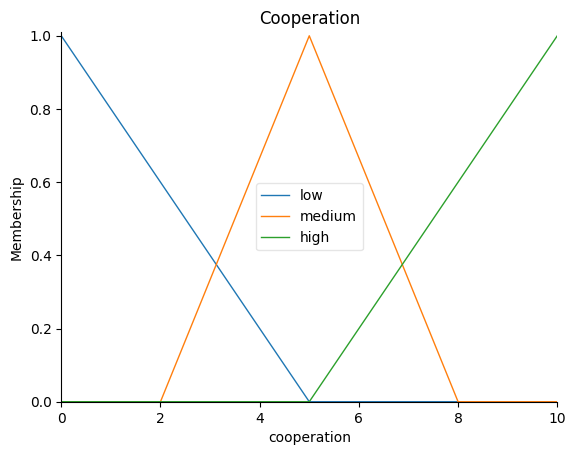

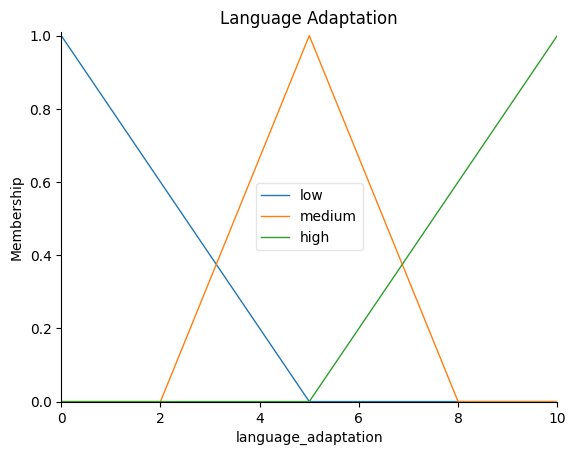

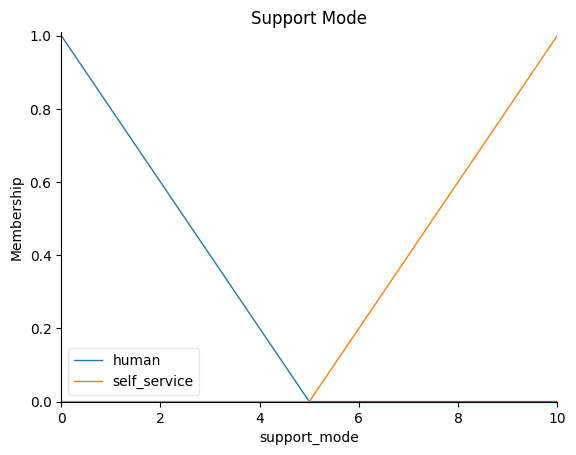

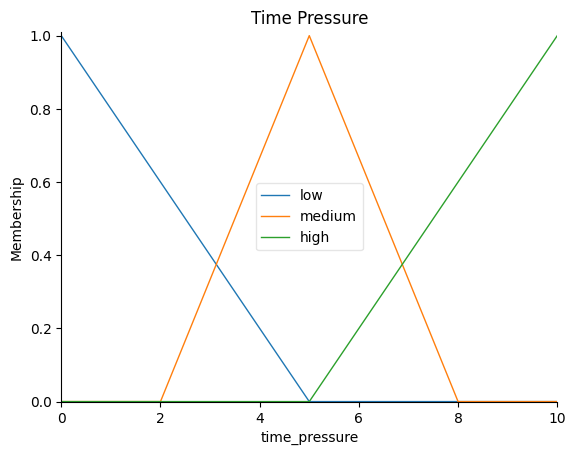

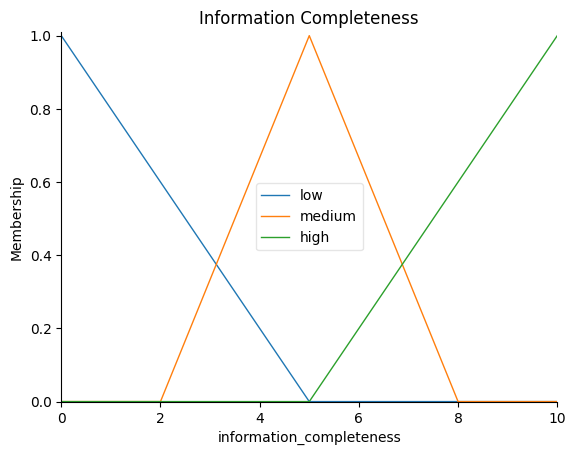

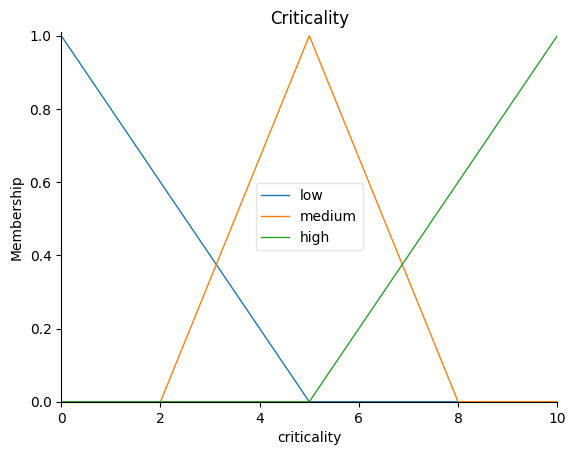

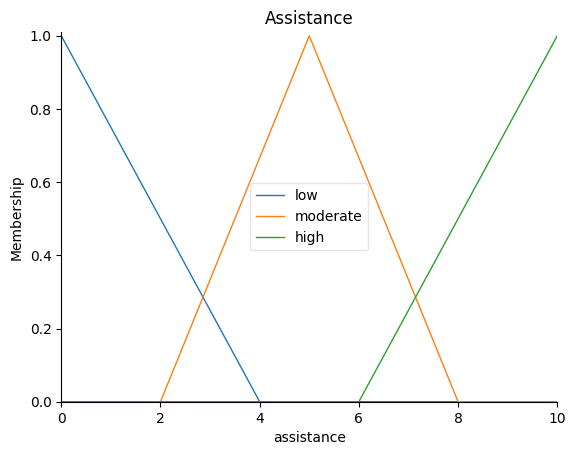

In [2]:
universe = np.arange(0, 10.1, 0.1)

def make_input(name):
    variable = ctrl.Antecedent(universe, name)
    variable["low"] = fuzz.trimf(variable.universe, [0, 0, 5])
    variable["medium"] = fuzz.trimf(variable.universe, [2, 5, 8])
    variable["high"] = fuzz.trimf(variable.universe, [5, 10, 10])
    return variable

proficiency = make_input("proficiency")
familiarity = make_input("familiarity")
stress = make_input("stress")

cooperation = make_input("cooperation")
language_adaptation = make_input("language_adaptation")
support_mode = ctrl.Antecedent(universe, "support_mode")
support_mode["human"] = fuzz.trimf(universe, [0, 0, 5])
support_mode["self_service"] = fuzz.trimf(universe, [5, 10, 10])

time_pressure = make_input("time_pressure")
information_completeness = make_input("information_completeness")
criticality = make_input("criticality")

assistance = ctrl.Consequent(universe, "assistance")
assistance["low"] = fuzz.trimf(assistance.universe, [0, 0, 4])
assistance["moderate"] = fuzz.trimf(assistance.universe, [2, 5, 8])
assistance["high"] = fuzz.trimf(assistance.universe, [6, 10, 10])

for variable in [proficiency, familiarity, stress, cooperation, language_adaptation,
                 support_mode, time_pressure, information_completeness, criticality, assistance]:
    variable.view()
    plt.title(variable.label.replace("_", " ").title())
    plt.show()


## Define the fuzzy rules
1. Our rules decide how much help the user needs based on their language level, familiarity, stress, and the situation

2. When the situation is urgent, TravelEase gives clear, short instructions. If the user is struggling, it provides more detailed guidance


In [3]:
rules = [
    ctrl.Rule(
        time_pressure["low"] & proficiency["medium"],
        assistance["high"]
    ),

    ctrl.Rule(
        time_pressure["high"] | stress["high"],
        assistance["low"]
    ),

    ctrl.Rule(proficiency["low"], assistance["high"]),
    ctrl.Rule(proficiency["medium"], assistance["moderate"]),
    ctrl.Rule(proficiency["high"] & stress["low"], assistance["low"]),

    ctrl.Rule(familiarity["low"], assistance["high"]),
    ctrl.Rule(familiarity["medium"], assistance["moderate"]),
    ctrl.Rule(familiarity["high"] & stress["low"], assistance["low"]),

    ctrl.Rule(cooperation["low"], assistance["high"]),
    ctrl.Rule(cooperation["medium"], assistance["moderate"]),
    ctrl.Rule(cooperation["high"] & language_adaptation["high"],
              assistance["low"]),

    ctrl.Rule(language_adaptation["low"], assistance["high"]),
    ctrl.Rule(language_adaptation["medium"], assistance["moderate"]),

    ctrl.Rule(support_mode["human"] & cooperation["high"],
              assistance["low"]),
    ctrl.Rule(support_mode["self_service"] & language_adaptation["low"],
              assistance["high"]),

    ctrl.Rule(information_completeness["low"], assistance["high"]),
    ctrl.Rule(information_completeness["medium"], assistance["moderate"]),
    ctrl.Rule(information_completeness["high"] & criticality["low"],
              assistance["low"]),

    ctrl.Rule(criticality["high"], assistance["high"]),
    ctrl.Rule(criticality["medium"], assistance["moderate"])
]

print(f"TravelEase rules defined: {len(rules)}")


TravelEase rules defined: 20


## Testing TravelEase with real examples

In [4]:
control_system = ctrl.ControlSystem(rules)

test_cases = [
    {
        "name": "Confusing train platform (human help unavailable)",
        "values": dict(
            proficiency=2, familiarity=2, stress=8, cooperation=3,
            language_adaptation=3, support_mode=10, time_pressure=7,
            information_completeness=2, criticality=6
        ),
    },
    {
        "name": "Buying a snack (cooperative staff)",
        "values": dict(
            proficiency=6, familiarity=5, stress=3, cooperation=8,
            language_adaptation=8, support_mode=0, time_pressure=3,
            information_completeness=7, criticality=2
        ),
    },
    {
        "name": "Reading a simple sign (self-service)",
        "values": dict(
            proficiency=8, familiarity=8, stress=1, cooperation=5,
            language_adaptation=5, support_mode=10, time_pressure=2,
            information_completeness=9, criticality=1
        ),
    },
    {
        "name": "Finding a bus at an unfamiliar station",
        "values": dict(
            proficiency=4, familiarity=2, stress=6, cooperation=5,
            language_adaptation=5, support_mode=10, time_pressure=8,
            information_completeness=3, criticality=6
        ),
    },
]

results = []

for case in test_cases:
    sim = ctrl.ControlSystemSimulation(control_system)

    for name, value in case["values"].items():
        sim.input[name] = value

    sim.compute()

    score = float(sim.output["assistance"])
    results.append((case["name"], score))
    print(f'{case["name"]}: assistance score = {score:.2f}/10')

print("Number of rules:", len(rules))

Confusing train platform (human help unavailable): assistance score = 5.00/10
Buying a snack (cooperative staff): assistance score = 4.70/10
Reading a simple sign (self-service): assistance score = 3.63/10
Finding a bus at an unfamiliar station: assistance score = 5.00/10
Number of rules: 20


## Comparing the results

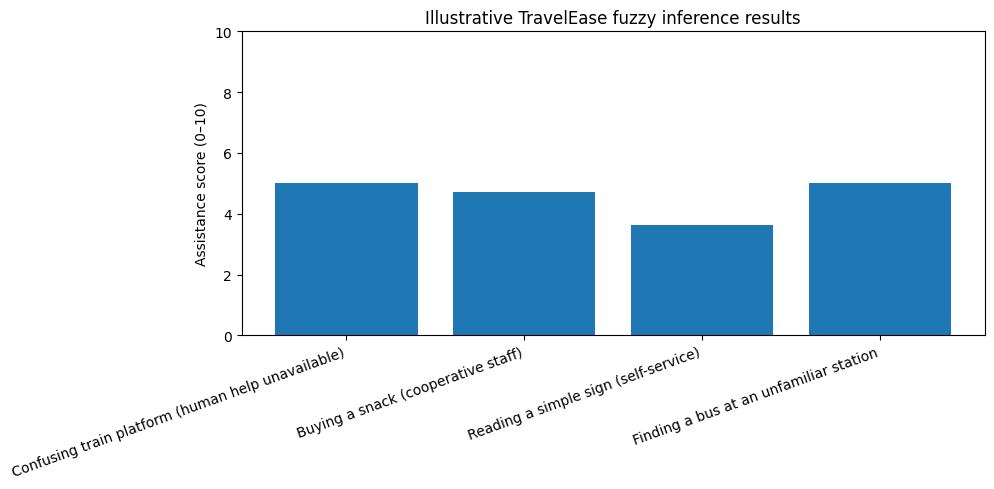

In [5]:
labels = [item[0] for item in results]
scores = [item[1] for item in results]
plt.figure(figsize=(10, 5))
plt.bar(labels, scores)
plt.ylim(0, 10)
plt.ylabel("Assistance score (0–10)")
plt.title("Illustrative TravelEase fuzzy inference results")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()


## Seeing how language level affects the help

Proficiency=1: assistance=5.18/10
Proficiency=3: assistance=4.68/10
Proficiency=5: assistance=4.27/10
Proficiency=7: assistance=4.21/10
Proficiency=9: assistance=3.69/10


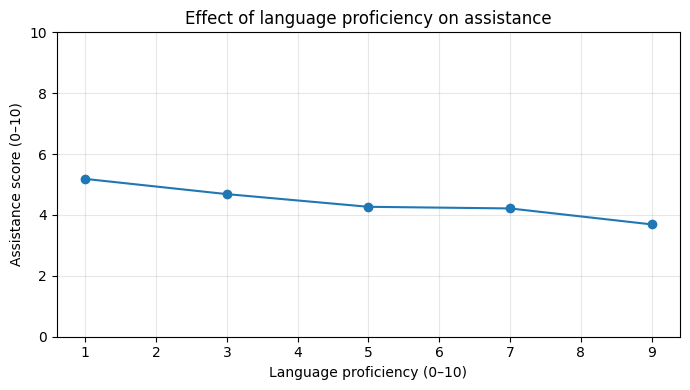

In [6]:
proficiency_values = [1, 3, 5, 7, 9]
scores_by_proficiency = []

fixed_values = dict(
    familiarity=7.5,
    stress=2,
    cooperation=8,
    language_adaptation=8,
    support_mode=0,
    time_pressure=4,
    information_completeness=6,
    criticality=2
)

for value in proficiency_values:
    for name, fixed_value in fixed_values.items():
        sim.input[name] = fixed_value

    sim.input["proficiency"] = value
    sim.compute()

    score = float(sim.output["assistance"])
    scores_by_proficiency.append(score)
    print(f"Proficiency={value}: assistance={score:.2f}/10")

plt.figure(figsize=(7, 4))
plt.plot(proficiency_values, scores_by_proficiency, marker="o")
plt.xlabel("Language proficiency (0–10)")
plt.ylabel("Assistance score (0–10)")
plt.title("Effect of language proficiency on assistance")
plt.ylim(0, 10)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [9]:
"""ChatGPT was used to help me identify and fix issues in my Python code and helped me rewrite the rules in my travelEase notebook to match my presentation.
It also helped me understand the scores and graphs produced by my notebook."""

'ChatGPT was used to help me identify and fix issues in my Python code and helped me rewrite the rules in my travelEase notebook to match my presentation.\nIt also helped me understand the scores and graphs produced by my notebook.'